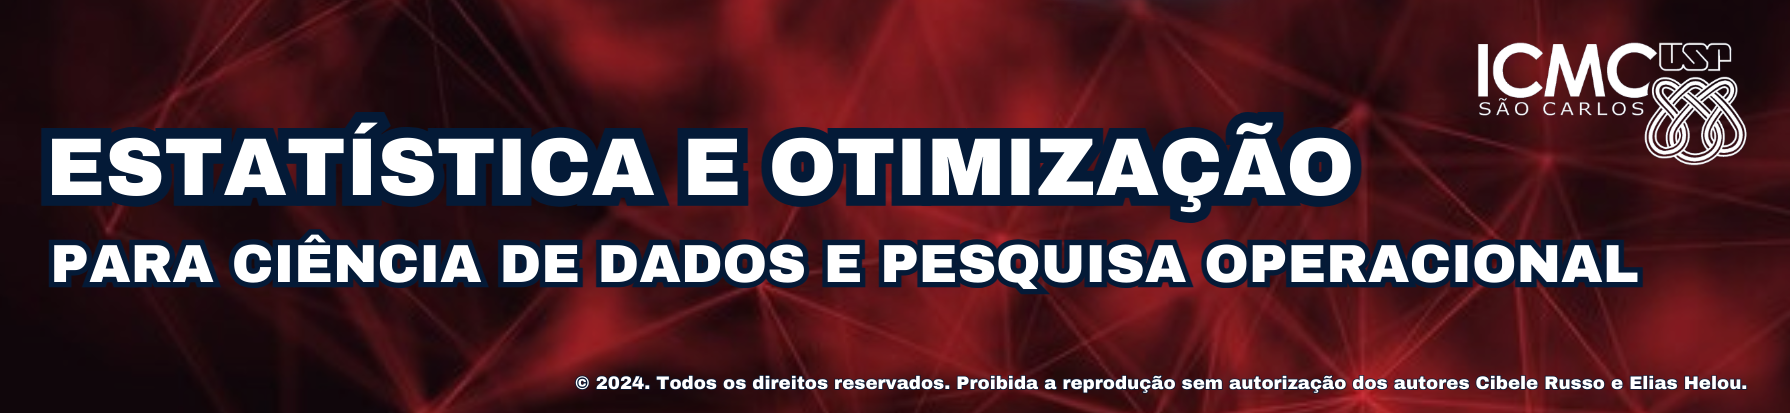


#  Inferência Bayesiana


por **Cibele Russo**

**ICMC/USP - São Carlos SP**



## Programa


- O paradigma Bayesiano.

- Os diferentes tipos de prioris.

- Distribuições conjugadas.

- Estimação Bayesiana.

- Densidade preditiva.

- Computação Bayesiana.

- Aplicações com PyMC.


**Referências e leituras recomendadas:**

1. Migon, H. S., Gamerman, D. and Louzada, F. (2014). Statistical Inference: An Integrated Approach, Second Edition, CRC Press.

2. Caffo, B. (2016). Statistical Inference for Data Science. Leanpub.
Disponível em https://leanpub.com/LittleInferenceBook

3. https://pt.wikipedia.org/wiki/Infer%C3%AAncia_bayesiana

4. https://www.pymc.io/



## O paradigma Bayesiano

Seja uma amostra aleatória $X_1,\ldots, X_n$ que vem de um modelo $p(x|\theta)$, $\theta \in \Theta$ e sejam $x_1,\ldots,x_n$ os dados observados.


Sob o **paradigma clássico ou frequentista**, $\theta$ é um **parâmetro fixo e desconhecido**.

Sob o **paradigma Bayesiano**, consideramos modelos probabilísticos para **representar a incerteza** a respeito de $\theta$.

Se temos informação **a priori** sobre o parâmetro $\theta$, antes de observar os dados, por que não usá-la?



### Exemplo:

Na aplicação de Dados e decisões, suponha que antes de observar os dados, exista um conhecimento prévio de que a proporção p de salários acima de R$ 10.000,00 esteja em torno de 25\%. Como incorporar esse conhecimento prévio? Uma possibilidade seria considerar uma distribuição a priori beta para a proporção p.

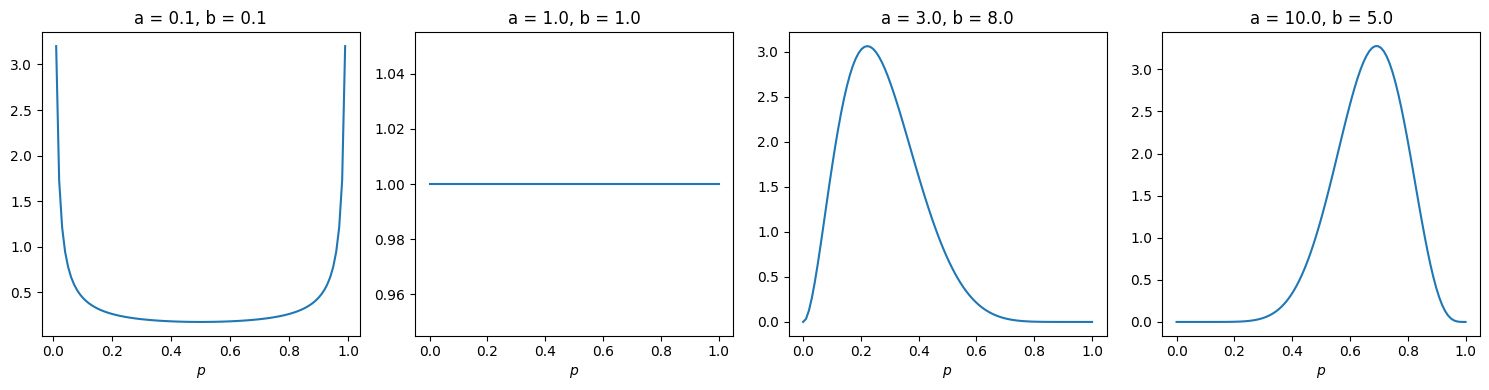

In [1]:
# Mais sobre a distribuição beta: https://pt.wikipedia.org/wiki/Distribui%C3%A7%C3%A3o_beta

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import beta

# Conjuntos de parâmetros da distribuição a priori para a proporção de pessoas com salário maior que 10 mil
a_b_params = ((0.1, 0.1), (1, 1), (3, 8), (10, 5))
p = np.linspace(0, 1, 100)

# Plota as densidades da beta para cada conjunto de parâmetros
plt.figure(figsize=(15,4))
for i, (a, b) in enumerate(a_b_params):
    plt.subplot(1, len(a_b_params), i+1)

    prior = beta(a, b)

    plt.plot(p, prior.pdf(p))
    plt.xlabel(r'$p$')
    plt.title("a = {:.1f}, b = {:.1f}".format(a, b))
    plt.tight_layout()


### Teorema de Bayes

Ver, por exemplo: https://pt.wikipedia.org/wiki/Teorema_de_Bayes


Sejam

- $p(\theta)$ a **distribuição a priori** para $\theta$.

- $l(\theta,x) = p(x|\theta)$ a **verossimilhança** de $\theta$.

- $p(\theta|x)$ a **distribuição a posteriori** de $\theta$.

O Teorema de Bayes ilustra o aumento de informação com a introdução do conhecimento a priori

$$p(\theta|x) = \displaystyle \frac{p(x,\theta)}{p(x)} = \frac{p(x|\theta)p(\theta)}{p(x)} = \frac{p(x|\theta) p(\theta)}{\displaystyle\int p(\theta,x) d\theta}.$$






Em outras palavras:

distribuição a posteriori $\propto$ verossimilhança $\times$ distribuição a priori





Para um valor fixo de $x$, as duas fontes de informação para $\theta$ são

- a função $l(\theta;x)=p(x|\theta)$ fornece a plausibilidade ou verossimilhança de cada um dos possíveis valores de $\theta$ e

- $p(\theta)$ é chamada distribuição a priori de $\theta$,

que, combinadas, levam à distribuição a posteriori de $\theta$, $p(\theta|x)$.




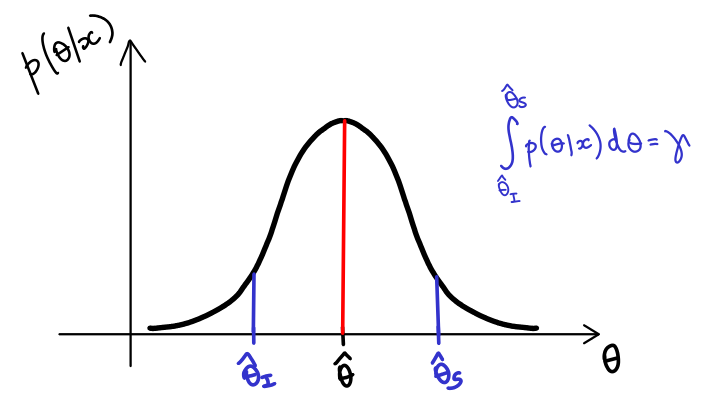

Para $x$ fixo, a **verossimilhança**  fornece a **plausibilidade** de cada um dos possíveis valores de $\theta$.

Já a **distribuição a priori** $p(\theta)$ incorpora o **conhecimento do pesquisador**.

Essas duas quantidades combinadas são levadas à **distribuição a posteriori** de $\theta$.

A **distribuição a posteriori** de $\theta$ dados $x_1,\ldots,x_n$ observados é dada por:

$$p(\theta|x_1,\ldots,x_n) = \displaystyle\frac{p(x_1,\ldots,x_n|\theta)p(\theta)}{\int_{\Theta} p(x_1,\ldots,x_n|\theta)p(\theta)d\theta}$$




- $p(x_1,\ldots,x_n|\theta) = \displaystyle\prod_{i=1}^n p(x_i|\theta)  = L(\theta|x_1,\ldots,x_n)$ é a **função de verossimilhança** de $\theta$.


- O denominador $$\int_{\Theta} p(x_1,\ldots,x_n|\theta)p(\theta)d\theta = C(x_1,\ldots,x_n).$$


É comum escrever que


$p(\theta|x_1,\ldots,x_n) = \displaystyle\frac{ L(\theta|x_1,\ldots,x_n) p(\theta)}{ C(x_1,\ldots,x_n)}\propto L(\theta|x_1,\ldots,x_n) p(\theta)$,



## Distribuição preditiva

A constante normalizadora da posteriori pode ser facilmente recuperada pois $p(\theta|x)=kp(x|\theta)p(\theta)$ onde

$k^{-1}= \int p(x|\theta)p(\theta)d\theta=E_\theta[p(X|\theta)]= p(x)$

chamada **distribuição preditiva** (ou marginal) de $X$.


Esta é a distribuição esperada para a observação $x$ dado $\theta$. Assim,

- Antes de observar $X$ podemos checar a adequação da priori fazendo predições via $p(x)$.

- Se $X$ observado recebia pouca probabilidade preditiva então o modelo deve ser questionado, revisado, ou existe observação aberrante.




Se, após observar $X=x$, estamos interessados na previsão de uma quantidade $Y$, também relacionada com $\theta$, e descrita probabilisticamente por $p(y|\theta)$ então

$$p(y|x)=\int p(y,\theta| x)d\theta =\displaystyle \int p(y|\theta,x)p(\theta| x)d\theta$$

Os conceitos de priori e posteriori são relativos àquela observação que está sendo considerada no momento. Assim, $p(\theta| x)$ é a posteriori de $\theta$ em relação a $X$ (que já foi observado) mas é a priori de $\theta$ em relação a $Y$ (que não foi observado ainda).

Após observar $Y=y$ uma nova posteriori (relativa a $X=x$ e $Y=y$) é obtida aplicando-se novamente o teorema de Bayes.




**Exemplo** (Gamerman e Migon, 1993)

Um médico "desconfia" que um paciente pode ter uma doença. Baseado na sua experiência, no seu conhecimento sobre esta doença e nas informações dadas pelo paciente, **ele assume que a probabilidade do paciente ter a doença é 0.7**. A quantidade de interesse, desconhecida, é definida como

$\theta = \left\{\begin{array}{l} 1,\quad \text{se o paciente tem a doença,} \\ 0,\quad \text{se o paciente não tem a doença.}\end{array}\right.$


Para aumentar sua quantidade de informação sobre a doença o médico faz um exame $X$ relacionado com $\theta$ através da distribuição

$P(X=1|\theta=0)=0.40$   e

$P(X=1|\theta=1)=0.95$

e o resultado do exame foi positivo (ou seja, observou-se $X=1$).

É bem intuitivo que a probabilidade de doença deve ter aumentado após este resultado e a questão aqui é quantificar este aumento. Usando o teorema de Bayes, segue que

$P(\theta=1|X=1)\propto l(\theta=1;X=1)p(\theta=1)=(0.95)(0.7)=0.665$

$P(\theta=0|X=1)\propto l(\theta=0;X=1)p(\theta=0)=(0.40)(0.3)=0.120.$

A constante normalizadora é tal que $P(\theta=0|X=1)+P(\theta=1|X=1)=1$, i.e.,

$k(0.665)+k(0.120)=1$ e $k=1/0.785$.

Portanto, a distribuição a posteriori de $\theta$ é

$P(\theta=1|X=1)=0.665/0.785=0.847$

$P(\theta=0|X=1)=0.120/0.785=0.153.$

O aumento na probabilidade de doença não foi muito grande porque a verossimilhança $l(\theta=0;X=1)$ também era grande (o modelo atribuia uma plausibilidade grande para $\theta=0$ mesmo quando $X=1$).

Agora o médico aplica outro exame $Y$ cujo resultado está relacionado a $\theta$ através da seguinte distribuição

$P(Y=1|\theta=0)=0.04$   e

$P(Y=1|\theta=1)=0.99.$

Mas antes de observar o resultado deste exame é interessante obter sua distribuição preditiva.

Como $\theta$ é uma quantidade discreta segue que

$p(y|x)=\sum_\theta p(y|\theta)p(\theta|x)$

e note que $p(\theta|x)$ é a priori em relação a $Y$.


Assim,


$P(Y=1|X=1)=P(Y=1|\theta=0)P(\theta=0|X=1)+P(Y=1|\theta=1)P(\theta=1|X=1)$

$=(0.04)(0.153) + (0.99)(0.847) = 0.845$

$P(Y=0|X=1)=1-P(Y=1|X=1) = 0.155.$

O resultado deste exame foi negativo ($Y=0$).

Neste caso, é também intuitivo que a probabilidade de doença deve ter diminuido e esta redução será quantificada por uma nova aplicação do teorema de Bayes,

$P(\theta=1|X=1,Y=0)\propto\displaystyle l(\theta=1;Y=0)P(\theta=1|X=1)\propto\displaystyle (0.01)(0.847)=0.0085$

$P(\theta=0|X=1,Y=0)\propto\displaystyle l(\theta=0;Y=0)P(\theta=0|X=1)\propto\displaystyle (0.96)(0.153)=0.1469.$

A constante normalizadora é $1/(0.0085+0.1469)=1/0.1554$ e assim a distribuição a posteriori de $\theta$ é

$P(\theta=1|X=1,Y=0)=0.0085/0.1554=0.055$

$P(\theta=0|X=1,Y=0)=0.1469/0.1554=0.945.$

Verifique como a probabilidade de doença se alterou ao longo do experimento


$P(\theta=1) = \left\{\begin{array}{ll} 0.7 & \text{antes dos exames}\\0.847 & \text{após o exames X}\\ 0.055 & \text{após X e Y}\end{array}\right.$



Note também que o valor observado de $Y$ recebia pouca probabilidade preditiva. Isto pode levar o médico a repensar o modelo, i.e.,

(i) Será que $P(\theta =1)=0.7$ é uma priori adequada?

(ii) Será que as distribuições amostrais de $X$ e $Y$ estão corretas? O teste $X$ é tão inexpressivo e $Y$ é realmente tão poderoso?


## Os diferentes tipos de prioris


Destacamos as distribuições a priori

- **Priori não-informativa**
    - Uniforme
    - Priori vaga (às vezes imprópria)

- **Priori informativa**
    - Conhecimento do pesquisador dá informação sobre os parâmetros

- **Priori conjugada**
    - Priori e posteriori tem a mesma distribuição, a menos dos parâmetros (em geral facilita os cálculos)

### Distribuições conjugadas

Leitura recomendada:

- Conjugate prior, por Marco Taboga: https://www.statlect.com/fundamentals-of-statistics/conjugate-prior



Vantagem de usar distribuições a priori conjugadas: principalmente **ganho de custo computacional.**
|                          | Priori     | Núcleo da Verossimilhança | Posteriori |
|--------------------------|------------|----------------------------|------------|
|$\theta$ proporção     | Beta       | Bernoulli                  | Beta       |
|$\theta$ média         | Normal     | Normal                     | Normal     |
| taxa de falha            | Gama       | Poisson                    | Gama       |
|                          | Dirichlet  | Multinomial                | Dirichlet  |


### Exemplo de priori conjugada beta-Bernoulli

No exemplo de Dados e Decisões, se considerarmos que

- $X=\left\{ \begin{array}{lll} 1, &\text{se o funcionário ganha mais que 10 mil reais,} \\ 0, &\text{caso contrário.} \end{array}\right.$


- $X \sim Bernoulli(p)$


- Verossimilhança:

Para $n$ suficientemente grande, pelo TLC sabemos que a distribuição amostral de $\bar{X}$ se aproxima da normal (será usada para graficar a verossimilhança) $$\bar{X} \sim N\left(p, \displaystyle{\frac{p(1-p)}{n}}\right).$$


Além disso, $Y = \sum_{i=1}^{n} X_i \sim binomial(n, p)$.




- Priori: $p \sim beta(3, 8)$


- Posteriori: $p|k \sim beta(k+a, n-k+b)$

onde $k$ é o número de sucessos observados na amostra.



In [2]:
import pandas as pd

# Dados banco - Leitura dos dados
dados = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Datasets/refs/heads/main/DadoseDecisoes.csv', index_col=0)

dados['Salario_Bin'] = (dados['Salário'] > 10000).astype(int)

dados.head()

,Idade,Gênero,Departamento,Salário,Horas_Trabalhadas,Produtividade,Satisfação,Tempo_Empresa,Cursos_Realizados,Home_Office,Salario_Bin
ID,,,,,,,,,,,
1,34,Masculino,RH,3848.89,36,84.89,94.33,0,4,Não,0
2,39,Feminino,Vendas,2536.32,48,107.84,98.62,4,9,Sim,0
3,39,Masculino,Marketing,7377.81,44,95.66,80.23,11,6,Sim,0
4,27,Feminino,Vendas,2536.32,40,88.89,94.63,8,1,Sim,0
5,41,Feminino,Vendas,2536.32,37,80.97,86.44,11,12,Não,0


In [3]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Vamos trabalhar com uma amostra
from scipy.stats import beta

a = 3
b = 8

amostra = dados.sample(n=10, replace=False, random_state=3)

n = len(amostra)
k = amostra['Salario_Bin'].sum()
posteriori = beta(a + k, n - k + b)

k/n

np.float64(0.2)

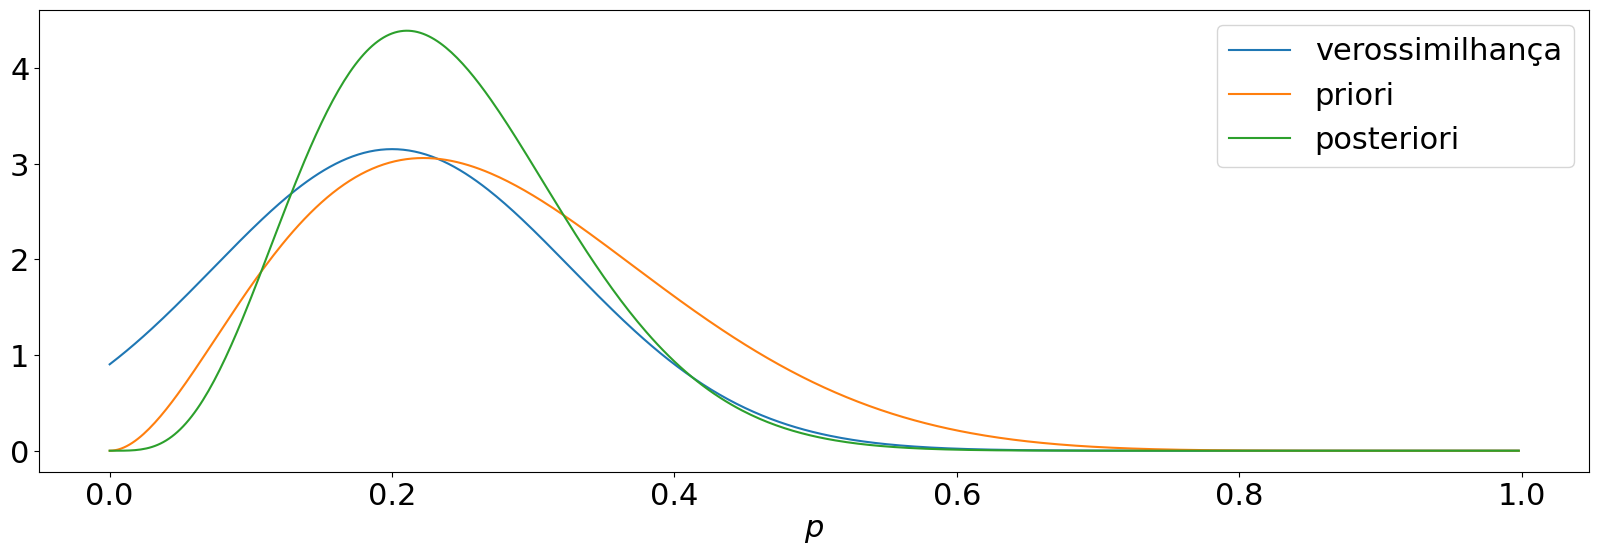

In [4]:
from scipy.stats import norm

# Eixo x entre 0 e 1 de .002 em .002.
x_axis = np.arange(0, 1, 0.002)

# Plota as densidades da beta para cada conjunto de parâmetros
plt.figure(figsize=(20,6))

prior = beta(a, b)

p_chapeu = amostra['Salario_Bin'].mean()
dp = np.sqrt(p_chapeu*(1-p_chapeu)/n)

media = p_chapeu
dp = np.sqrt(media*(1-media)/n)

plt.s = 0
plt.rcParams.update({'font.size': 22})

plt.plot(x_axis, norm.pdf(x_axis, media, dp), label='verossimilhança')
plt.plot(x_axis, prior.pdf(x_axis), label='priori')
plt.plot(x_axis, posteriori.pdf(x_axis), label='posteriori')
plt.xlabel(r'$p$')
plt.legend()


In [5]:
# Estimador bayesiano EAP (Esperança a posteriori)
print('Média: %.2f' % posteriori.mean())

# E para calcular um intervalo de credibilidade, decidimos uma probabilidade
# Por exemplo 95% para a credibilidade
# Uma maneira seria definir que 2,5% de cada cauda como os limites do intervalo (chamado intervalo simétrico)
# Este método é válido quando a posteriori se aproxima de uma distribuição simétrica, pois nesse caso tende a gerar o intervalo com menor amplitude
# A seguir, apresentamos outra solução com um intervalo de credibilidade de menor amplitude.

LI = posteriori.ppf(.025)
LS = posteriori.ppf(.975)
print("Intervalo com 95% de credibilidade: ({:.3f}, {:.3f})".format(LI,LS))


Média: 0.24
Intervalo com 95% de credibilidade: (0.087, 0.437)



    
## Estimação Bayesiana


Leituras recomendadas:

- Inferência Estatística: Introdução à Inferência Bayesiana. Stuart Coles
Paulo Justiniano Ribeiro Jr. Disponível em: http://www.leg.ufpr.br/~paulojus/ce227/InferenciaBayesiana.pdf

- Notas Ricardo Ehlers e Paulo Justiniano: http://www.leg.ufpr.br/~paulojus/CE227/ce227/node1.html

- Migon, H. S., Gamerman, D. and Louzada, F. (2014). Statistical Inference: An Integrated Approach, Second Edition, CRC Press.


### Introdução à Teoria da Decisão

Um problema de decisão fica completamente especificado pela descrição dos seguintes espaços:

(i) Espaço do parâmetro ou estados da natureza, $\Theta$.
    
(ii) Espaço dos resultados possíveis de um experimento, $\Omega$.
    
(iii) Espaço de possíveis ações, $A$.

Uma regra de decisão $\delta$ é uma função definida em $\Omega$ que assume valores em $A$, i.e. $\delta:\Omega\rightarrow A$. A cada decisão $\delta$ e a cada possível valor do parâmetro $\theta$ podemos associar uma **perda** $L(\delta,\theta)$ assumindo valores positivos. Definimos assim uma **função de perda**.

**Definição:** O **risco de uma regra de decisão**, denotado por $R(\delta)$, é a **perda esperada a posteriori**, i.e. $$R(\delta)=E_{\theta\vert\mathbf{x}} [L(\delta,\theta)].$$

Uma regra de decisão $\delta^*$ é **ótima** se tem risco mínimo, i.e. $R(\delta^*)<R(\delta), ~\forall \delta$. Esta regra será denominada **regra de Bayes** e seu risco, **risco de Bayes**.



**Exemplo**:

Um laboratório farmaceutico deve decidir pelo lançamento ou não de uma nova droga no mercado. O laboratório só lançará a droga se achar que ela é eficiente mas isto é exatamente o que é desconhecido.

 Podemos associar um parâmetro $\theta$ aos estados da natureza:

- droga é eficiente ($\theta=1$),

- droga não é eficiente ($\theta=0$)

e as possíveis ações como


- lança a droga ($\delta=1$),

- não lança a droga ($\delta=0$).

 Suponha que foi possível construir a seguinte tabela de perdas levando em conta a eficiência da droga,

|                       | eficiente ($\theta=1$) | não eficiente ($\theta=0$) |
|-----------------------|--------------------------|-------------------------------|
| lança ($\delta=1$)  | -500                     | 600                           |
| não lança ($\delta=0$) | 1500                     | 100                           |

       

Vale notar que estas perdas traduzem uma **avaliação subjetiva** em relação à gravidade dos erros cometidos.

Suponha agora que a incerteza sobre os estados da natureza é descrita por

$P(\theta=1)=\pi$, $0<\pi<1$

avaliada na distribuição atualizada de $\theta$ (seja a priori ou a posteriori).


Note que, para $\delta$ fixo, $L(\delta,\theta)$ é uma variável aleatória discreta assumindo apenas dois valores com probabilidades $\pi$ e $1-\pi$.

Assim, usando a definição de risco obtemos que


$\displaystyle R(\delta=0) = \displaystyle E(L(0,\theta))=\pi 1500 +(1-\pi) 100 = 1400\pi + 100$

$\displaystyle R(\delta=1) = \displaystyle E(L(1,\theta))=\pi(-500)+(1-\pi) 600 =-1100\pi + 600$

Uma questão que se coloca aqui é, para que valores de $\pi$ a regra de Bayes será de lançar a droga.

Não é difícil verificar que as duas ações levarão ao mesmo risco, i.e.

$R(\delta=0)=R(\delta=1)$ se somente se $\pi=0.20$.

Além disso, para $\pi<0.20$ temos que $R(\delta=0)<R(\delta=1)$ e a regra de Bayes consiste em **não lançar a droga** enquanto que $\pi>0.20$ implica em $R(\delta=0)>R(\delta=1)$ e a regra de Bayes deve ser de **lançar a droga**.


### Estimadores de Bayes

Considere uma amostra aleatória $X_1,\dots,X_n$, tomada de uma distribuição com função de (densidade) de probabilidade $p(x\vert\theta)$, onde o valor do parâmetro $\theta$ é desconhecido.

Em um problema de inferência como este, o valor de $\theta$ deve ser estimado a partir dos valores observados na amostra.

Se $\theta\in\Theta$ então é razoável que os possíveis valores de um estimador $\widehat{\theta}(\mathbf{x})$ também devam pertencer ao espaço $\Theta$.

Além disso, um bom estimador é aquele para o qual, com alta probabilidade, apresenta o seguinte erro $$\widehat{\theta}(\mathbf{x})-\theta$$ próximo de zero.




### Funções de perda



Para cada possível valor de $\theta$ e cada possível estimativa $a\in\Theta$ vamos associar **uma perda** $L(a,\theta)$ de modo que quanto maior a distância entre $a$ e $\theta$ maior o valor da perda. A perda esperada a posteriori é dada por

$$E[L(a,\theta)\vert\mathbf{x}] = \int L(a,\theta)p(\theta\vert\mathbf{x}) d\theta$$

O **estimador de Bayes** será aquele que minimiza a perda esperada.


#### Função de perda quadrática

$$L(a,\theta)=(a-\theta)^2$$

O estimador de Bayes para $\theta$ será a **média de sua distribuição atualizada** (EAP: expected a posteriori).



#### Função de perda absoluta
(introduz punições que crescem linearmente com o erro de estimação)

$$L(a,\theta)=\vert a-\theta\vert$$

O estimador de Bayes para $\theta$ é a **mediana de sua distribuição atualizada**.



#### Função de perda 0-1

(associam uma perda fixa a um erro cometido, não importando sua magnitude)

$$L(a,\theta)=\left\{ \begin{array}{ccc} 1 &\text{se}& |a-\theta|>\epsilon \\ 0 &\text{se}& |a-\theta|<\epsilon \end{array}\right.$$

para todo $\epsilon>0$.

Neste caso, o estimador de Bayes é a **moda da distribuição atualizada de $\theta$** (MAP: maximum a posteriori).

A moda da posteriori de $\theta$ também é chamado de estimador de máxima verossimilhança generalizado (EMVG) e é o mais fácil de ser obtido dentre os estimadores vistos até agora.



**Exemplo:**

Suponha que queremos estimar a proporção $\theta$ de itens defeituosos em um grande lote. Para isto será tomada uma amostra aleatória $X_1,\dots,X_n$ de uma distribuição de Bernoulli com parâmetro $\theta$. Usando uma priori conjugada beta($a,b$), após observar a amostra a distribuição a posteriori é beta($a+k,b+n-k$) onde $k=\sum_{i=1}^n x_i$.

A média desta distribuição beta é dada por $(a+k)/(a+b+n)$ e portanto o estimador de Bayes de $\theta$ usando perda quadrática é

$\delta(\mathbf{x})= \displaystyle\frac{a+\sum_{i=1}^n X_i}{a+b+n}.$


### Estimação por Intervalos

Pode-se desenvolver a estimação por intervalos por meio do **intervalo de credibilidade (ou intervalo de confiança Bayesiano)** baseado no distribuição a posteriori.



**Definição:**

C é um **intervalo de credibilidade** de 100(1-$\alpha$)$\%$, ou nível de credibilidade (ou confiança) $1-\alpha$, para $\theta$ se $$P(\theta\in C)\ge 1-\alpha.$$



Obs: Quanto menor for o tamanho do intervalo, mais concentrada é a distribuição do parâmetro, ou seja o tamanho do intervalo informa sobre a dispersão de $\theta$.


O **intervalo com o menor comprimento possível** é obtido tomando-se os valores de $\theta$ com maior densidade a posteriori, e esta idéia é expressa matematicamente na definição abaixo.


**Definição:**

Um intervalo de credibilidade $C$ de 100(1-$\alpha$)% para $\theta$ é de **máxima densidade a posteriori (MDP)** se $$C=\{\theta\in\Theta:p(\theta\vert\mathbf{x})\ge k(\alpha)\}$$ onde $k(\alpha)$ é a maior constante tal que $P(\theta\in C)\ge 1-\alpha$.

Usando esta definição, todos os pontos dentro do intervalo MDP terão densidade maior do que qualquer ponto fora do intervalo.

Um problema com os intervalos MDP é que eles não são invariantes a transformações 1 a 1, a não ser para transformações lineares. O mesmo problema ocorre com intervalos de comprimento mínimo na inferência clássica.

## Computação Bayesiana

Leituras recomendadas:

- Métodos de Monte Carlo: https://pt.wikipedia.org/wiki/M%C3%A9todo_de_Monte_Carlo

- Notas Ricardo Ehlers e Paulo Justiniano: http://www.leg.ufpr.br/~paulojus/CE227/ce227/node1.html

- Salvatier, John; Wiecki, Thomas V.; Fonnesbeck, Christopher. Probabilistic programming in Python using PyMC3. PeerJ Computer Science, v. 2, p. e55, 2016. Disponível em https://peerj.com/articles/cs-55/. Acessado em 06/04/2021.


A obtenção de informações a partir da distribuição a posteriori dos parâmetros pode envolver a avaliação de probabilidades ou esperanças, que exigem métodos computacionais baseados em simulações, como

- Método de Monte Carlo simples

- Monte Carlo com função de importância,

- Algoritmo de Metropolis-Hastings,

- Amostrador de Gibbs,

- Método do Bootstrap Bayesiano,

- Monte Carlo via cadeias de Markov (MCMC),

- Monte Carlo Hamiltoniano (HMC),

- No-U-Turn Sampler (NUTS).


HMC e NUTS aproveitam as informações de gradiente da probabilidade e alcançam uma convergência muito mais rápida do que os métodos de amostragem tradicionais, especialmente para modelos mais complexos.

O pacote PyMC do Python usa a programação probabilística para executar os métodos de HMC como o NUTS. Esse tipo de programação permite a especificação flexível e ajuste de modelos estatísticos bayesianos com sintaxe intuitiva e legível, embora poderosa, que é próxima da sintaxe natural que os estatísticos usam para descrever modelos.






In [6]:
#!pip install theano
#!pip install --upgrade arviz
#!pip install scipy==1.11.4



In [7]:
#!pip install pymc

#### Importante: No google colab é necessário clicar em Ambiente de execução e Reiniciar sessão

<div style = "text-align: center">
    <img src = "Banner.png" width = "95%" style = "border: solid; border-radius: 10px"></img>
</div>

# Aplicações: Inferência Bayesiana




## Exemplo beta-Bernoulli: Modelagem de uma proporção

In [8]:
import pymc as pm
import numpy as np
import pandas as pd
import arviz as az

# Dados Dados e decisões - Leitura dos dados
dados = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Datasets/refs/heads/main/DadoseDecisoes.csv', index_col=0)
dados['Salario_Bin'] = (dados['Salário'] > 10000).astype(int)
dados = pd.get_dummies(dados, columns=['Gênero', 'Departamento', 'Home_Office'], drop_first=True)

# Depois converte qualquer coluna booleana (inclusive Home_Office) para 0/1
dados = dados.astype({col: int for col in dados.select_dtypes('bool').columns})
dados.columns

Index(['Idade', 'Salário', 'Horas_Trabalhadas', 'Produtividade', 'Satisfação',
       'Tempo_Empresa', 'Cursos_Realizados', 'Salario_Bin', 'Gênero_Masculino',
       'Departamento_RH', 'Departamento_TI', 'Departamento_Vendas',
       'Home_Office_Sim'],
      dtype='object')

In [9]:
dados

,Idade,Salário,Horas_Trabalhadas,Produtividade,Satisfação,Tempo_Empresa,Cursos_Realizados,Salario_Bin,Gênero_Masculino,Departamento_RH,Departamento_TI,Departamento_Vendas,Home_Office_Sim
ID,,,,,,,,,,,,,
1,34,3848.89,36,84.89,94.33,0,4,0,1,1,0,0,0
2,39,2536.32,48,107.84,98.62,4,9,0,0,0,0,1,1
3,39,7377.81,44,95.66,80.23,11,6,0,1,0,0,0,1
4,27,2536.32,40,88.89,94.63,8,1,0,0,0,0,1,1
5,41,2536.32,37,80.97,86.44,11,12,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
226,36,3711.26,34,81.89,76.52,9,1,0,0,1,0,0,0
227,21,2536.32,34,85.63,100.00,0,0,0,0,0,0,0,0
228,43,5717.90,38,86.55,82.46,12,11,0,0,0,0,1,0


In [10]:
with pm.Model() as model:
    p = pm.Beta("p", 2, 8) #priori
    obs = pm.distributions.discrete.Bernoulli("obs", p, observed=dados['Salario_Bin'])

    idata = pm.sample(2000, tune=1500, return_inferencedata=True)


Output()

In [11]:
az.summary(idata)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
p,0.292,0.03,0.239,0.347,0.001,0.0,1482.0,2398.0,1.0


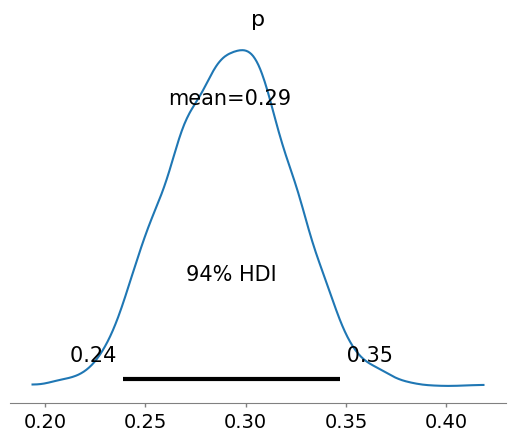

In [12]:
az.plot_posterior(idata);

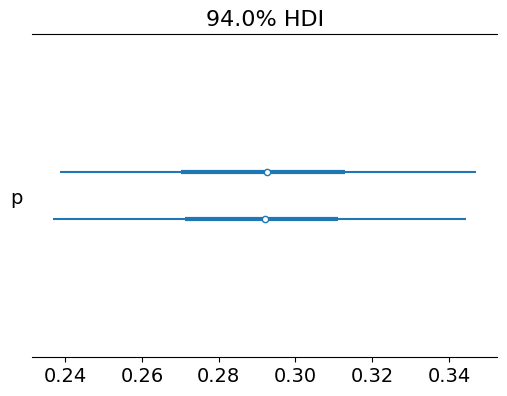

In [13]:
az.plot_forest(idata);

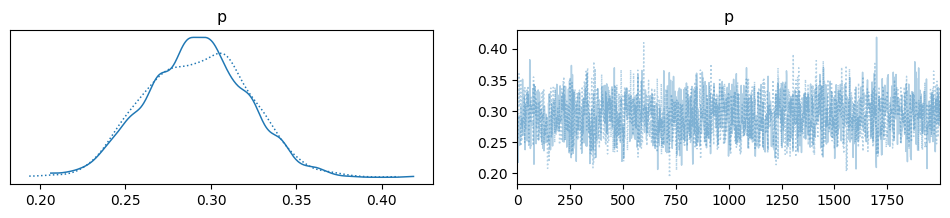

In [14]:
az.plot_trace(idata);

## Modelos lineares generalizados: um enfoque Bayesiano



### Modelo de regressão logística Bayesiano

In [15]:
import pymc as pm
import numpy as np

# Separando as variáveis explicativas
X1 = dados['Gênero_Masculino'].values
X2 = dados['Home_Office_Sim'].values
y = dados['Salario_Bin'].values

with pm.Model() as model:
    # Priori para coeficientes e intercepto
    beta1 = pm.Normal("beta1", mu=0, sigma=10)
    beta2 = pm.Normal("beta2", mu=0, sigma=10)
    intercept = pm.Normal("intercept", mu=0, sigma=10)

    # Logito e função logística
    logits = intercept + beta1 * X1 + beta2 * X2
    p = pm.Deterministic("p", pm.math.sigmoid(logits))

    # Verossimilhança
    obs = pm.Bernoulli("obs", p=p, observed=y)

    # Amostragem
    idata = pm.sample(2000, tune=1500, return_inferencedata=True)


Output()

In [16]:
import arviz as az

# Resumo estatístico dos parâmetros
az.summary(idata, var_names=["intercept", "beta1", "beta2"], round_to=2)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-2.01,0.32,-2.66,-1.45,0.01,0.01,1927.88,1987.87,1.0
beta1,0.77,0.31,0.23,1.40,0.01,0.01,1920.93,1822.79,1.0
beta2,1.19,0.31,0.61,1.78,0.01,0.01,2222.19,2257.13,1.0


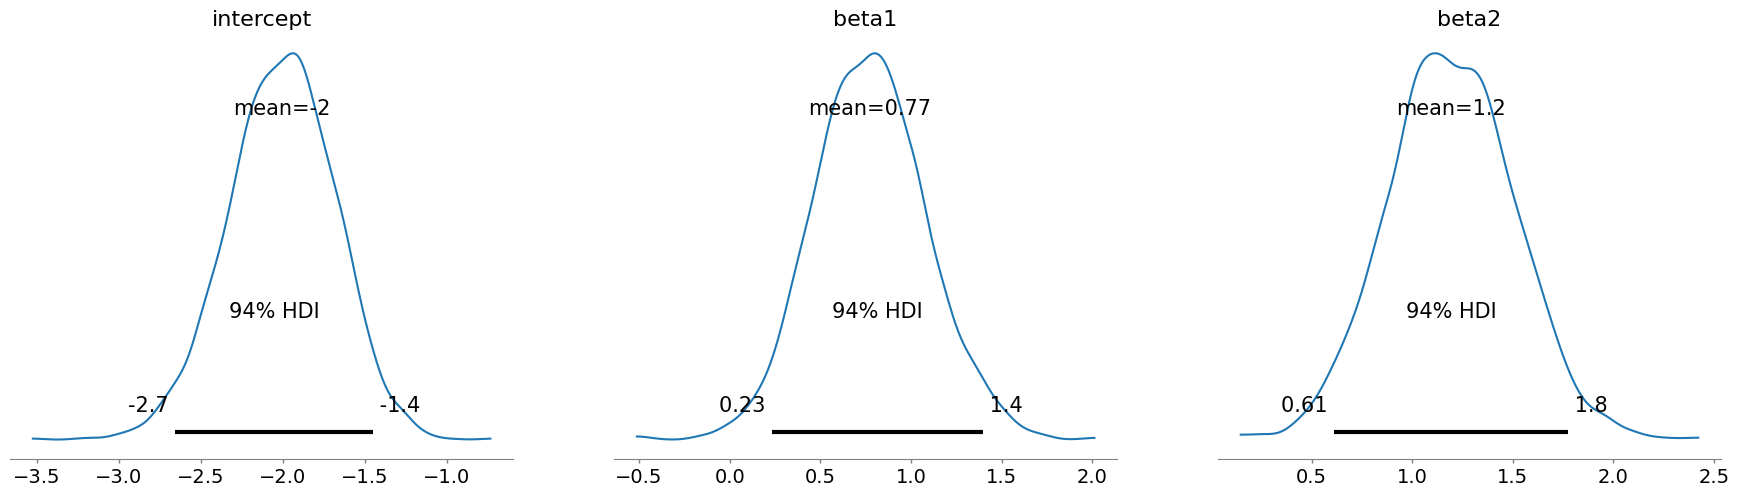

In [17]:
az.plot_posterior(idata, var_names=["intercept", "beta1", "beta2"]);

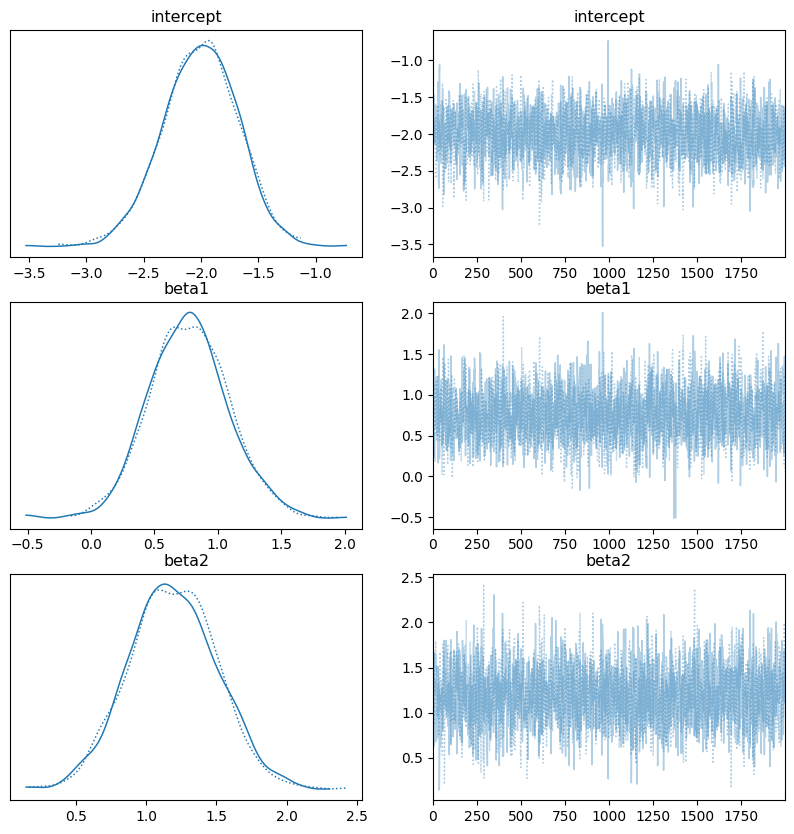

In [18]:
az.plot_trace(idata, var_names=["intercept", "beta1", "beta2"], figsize=(10, 10));
